1.確認 MSA 資料設計是否平衡。

2.計算 Two-way ANOVA。

3.分解 Repeatability、Operator、Interaction、Part-to-Part 的變異。

4.計算 Gauge R&R。

5.計算 %Contribution、%Study Variation、ndc。

6.輸出統計表格與圖表。

In [1]:
# Method: Crossed ANOVA Gauge R&R
#
# Experimental Design:
# 10 Parts (Wafers)
# 3 Operators
# 2 Repeated Measurements
# 1 Measurement Tool
#  Total observations = 10 * 3 * 2 = 60
#
# Objective:
# 1. Evaluate Repeatability
# 2. Evaluate Reproducibility
# 3. Evaluate Part-to-Part Variation
# 4. Calculate Total Gauge R&R
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import f

In [2]:
# ============================================================
# 1. Define Project Paths
# ============================================================
ROOT = Path.cwd().parent

DATA_DIR = ROOT / "content"
FIG_DIR = ROOT / "content" / "figures"
RESULT_DIR = ROOT / "content" / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Load MSA dataset
msa = pd.read_csv(DATA_DIR / "msa_data.csv")
sns.set_theme(style="whitegrid")

In [3]:
# ============================================================
# 2. Data Validation
# ============================================================

print("=" * 60)
print("MSA DATA VALIDATION")
print("=" * 60)

required_columns = [
    "wafer_id",
    "operator_id",
    "repeat",
    "measured_cd_nm"
]

# Check required columns
missing_columns = [
    col for col in required_columns
    if col not in msa.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Check missing values
if msa[required_columns].isnull().any().any():
    raise ValueError("Missing values found in MSA data.")

# Check duplicate measurement combinations
if msa.duplicated(
    subset=["wafer_id", "operator_id", "repeat"]
).any():
    raise ValueError(
        "Duplicate wafer/operator/repeat combinations found."
    )

# Get experimental design dimensions
n_parts = msa["wafer_id"].nunique()
n_operators = msa["operator_id"].nunique()

# Every wafer-operator combination must have the same
# number of repeated measurements.
replicate_counts = (
    msa.groupby(["wafer_id", "operator_id"])
    .size()
)

if replicate_counts.nunique() != 1:
    raise ValueError(
        "Unbalanced design: replicate counts are not equal."
    )

n_repeats = int(replicate_counts.iloc[0])

expected_records = (
    n_parts * n_operators * n_repeats
)

if len(msa) != expected_records:
    raise ValueError(
        "Unexpected number of observations."
    )

# This script assumes one measurement tool.
if "tool_id" in msa.columns:
    if msa["tool_id"].nunique() != 1:
        raise ValueError(
            "Crossed ANOVA model assumes one measurement tool."
        )

print(f"Number of Parts: {n_parts}")
print(f"Number of Operators: {n_operators}")
print(f"Repeated Measurements: {n_repeats}")
print(f"Total Observations: {len(msa)}")

print("\nData validation passed.")

MSA DATA VALIDATION
Number of Parts: 10
Number of Operators: 3
Repeated Measurements: 2
Total Observations: 60

Data validation passed.


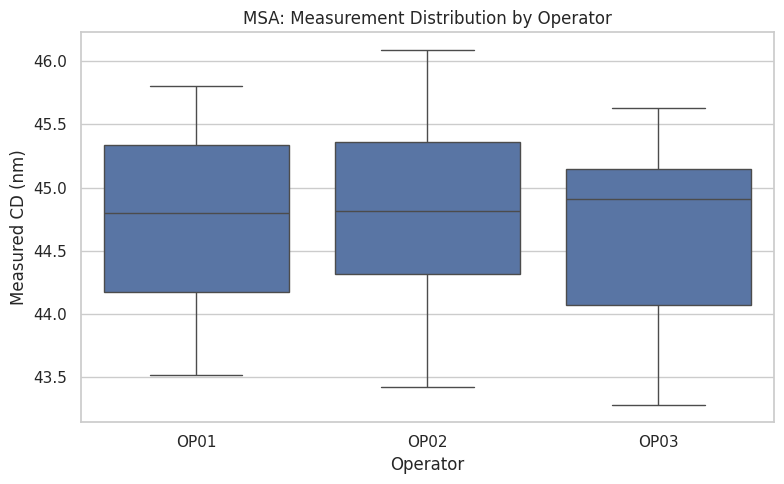

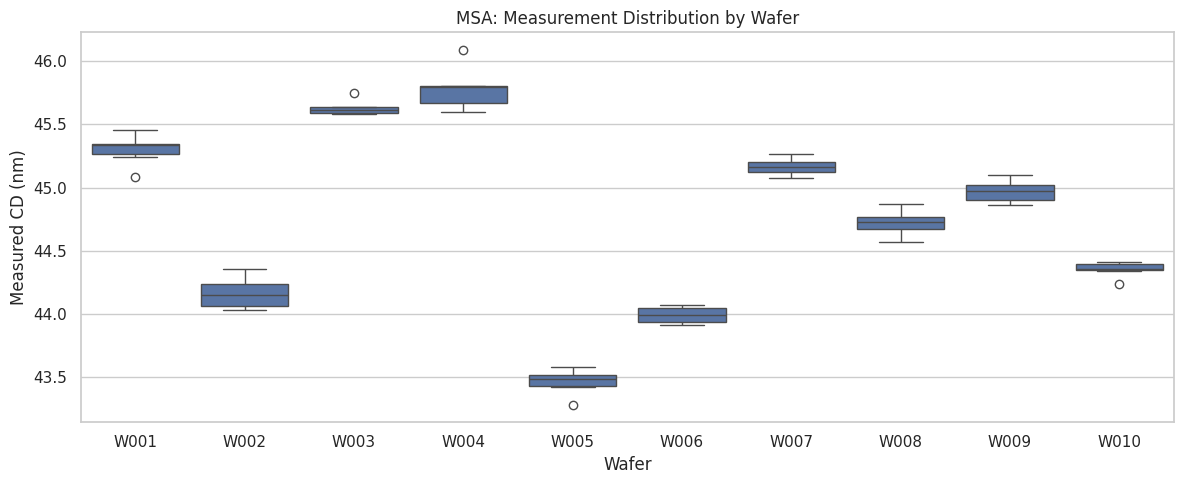

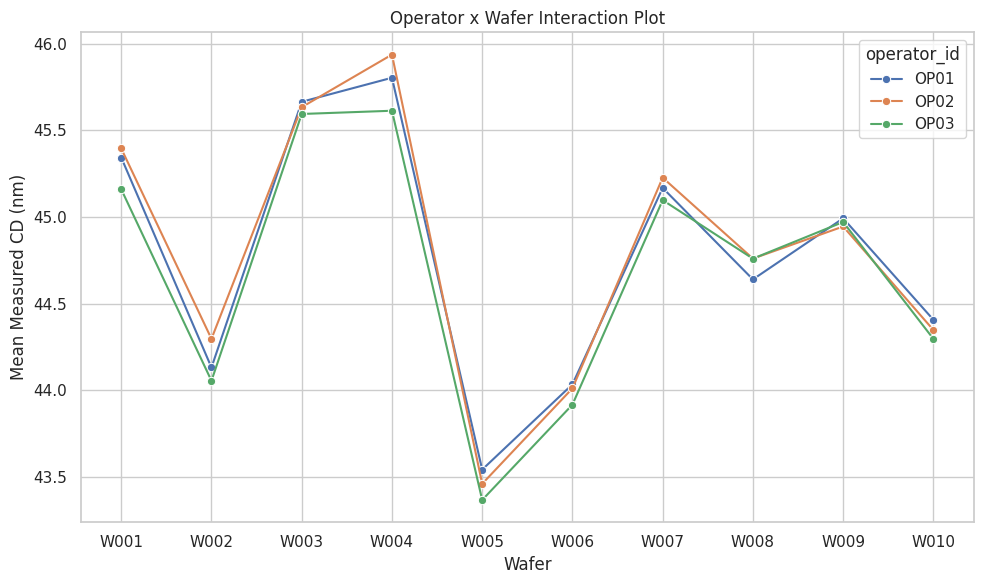

In [4]:
# ============================================================
# 3. Exploratory Visualization
# ============================================================

# ------------------------------------------------------------
# 3.1 Measurement Distribution by Operator
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=msa,
    x="operator_id",
    y="measured_cd_nm"
)

plt.xlabel("Operator")
plt.ylabel("Measured CD (nm)")
plt.title("MSA: Measurement Distribution by Operator")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "10_msa_operator_distribution.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# 3.2 Measurement Distribution by Wafer
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=msa,
    x="wafer_id",
    y="measured_cd_nm"
)

plt.xlabel("Wafer")
plt.ylabel("Measured CD (nm)")
plt.title("MSA: Measurement Distribution by Wafer")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "11_msa_wafer_distribution.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# 3.3 Operator x Wafer Interaction Plot
# ------------------------------------------------------------

# Calculate average measurement for each
# wafer-operator combination.

cell_means = (
    msa.groupby(["wafer_id", "operator_id"])
    ["measured_cd_nm"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=cell_means,
    x="wafer_id",
    y="measured_cd_nm",
    hue="operator_id",
    marker="o"
)

plt.xlabel("Wafer")
plt.ylabel("Mean Measured CD (nm)")
plt.title("Operator x Wafer Interaction Plot")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "12_operator_wafer_interaction.png",
    dpi=300
)

plt.show()

In [5]:
# ============================================================
# 4. Two-Way ANOVA Calculations
# ============================================================

# IMPORTANT:
# Use measured_cd_nm only.
#
# true_cd_nm is simulated ground truth.
# It is NOT included in Gauge R&R variance calculations.


# ------------------------------------------------------------
# 4.1 Calculate Grand Mean and Group Means
# ------------------------------------------------------------

grand_mean = msa["measured_cd_nm"].mean()

part_means = (
    msa.groupby("wafer_id")["measured_cd_nm"]
    .mean()
)

operator_means = (
    msa.groupby("operator_id")["measured_cd_nm"]
    .mean()
)

cell_means = (
    msa.groupby(["wafer_id", "operator_id"])
    ["measured_cd_nm"]
    .mean()
)


# ------------------------------------------------------------
# 4.2 Sum of Squares
# ------------------------------------------------------------

# Part-to-Part Sum of Squares
SS_part = (
    n_operators * n_repeats
    * ((part_means - grand_mean) ** 2).sum()
)

# Operator Sum of Squares
SS_operator = (
    n_parts * n_repeats
    * ((operator_means - grand_mean) ** 2).sum()
)

# Operator x Part Interaction Sum of Squares
SS_interaction = 0.0

for (part, operator), cell_mean in cell_means.items():

    interaction_effect = (
        cell_mean
        - part_means.loc[part]
        - operator_means.loc[operator]
        + grand_mean
    )

    SS_interaction += (
        n_repeats * interaction_effect ** 2
    )


# Repeatability / Residual Sum of Squares

# Calculate the corresponding cell mean for each observation.
msa["cell_mean"] = (
    msa.groupby(["wafer_id", "operator_id"])
    ["measured_cd_nm"]
    .transform("mean")
)

msa["residual"] = (
    msa["measured_cd_nm"] - msa["cell_mean"]
)

SS_repeatability = (
    msa["residual"] ** 2
).sum()


# ------------------------------------------------------------
# 4.3 Degrees of Freedom
# ------------------------------------------------------------

df_part = n_parts - 1

df_operator = n_operators - 1

df_interaction = (
    (n_parts - 1) * (n_operators - 1)
)

df_repeatability = (
    n_parts * n_operators * (n_repeats - 1)
)

# Total degrees of freedom
df_total = len(msa) - 1


# ------------------------------------------------------------
# 4.4 Mean Squares
# ------------------------------------------------------------

MS_part = SS_part / df_part
MS_operator = SS_operator / df_operator

MS_interaction = ( SS_interaction / df_interaction)
MS_repeatability = ( SS_repeatability / df_repeatability)

In [6]:
# ============================================================
# 5. ANOVA Table
# ============================================================

# F-tests for the crossed random-effects model:
#
# Part effect: MS_part / MS_interaction
# Operator effect: MS_operator / MS_interaction
# Interaction: MS_interaction / MS_repeatability

anova_rows = [
    {
        "Source": "Part",
        "SS": SS_part,
        "DF": df_part,
        "MS": MS_part,
        "F": MS_part / MS_interaction,
        "p_value": f.sf(
            MS_part / MS_interaction,
            df_part,
            df_interaction
        )
    },
    {
        "Source": "Operator",
        "SS": SS_operator,
        "DF": df_operator,
        "MS": MS_operator,
        "F": MS_operator / MS_interaction,
        "p_value": f.sf(
            MS_operator / MS_interaction,
            df_operator,
            df_interaction
        )
    },
    {
        "Source": "Part x Operator",
        "SS": SS_interaction,
        "DF": df_interaction,
        "MS": MS_interaction,
        "F": MS_interaction / MS_repeatability,
        "p_value": f.sf(
            MS_interaction / MS_repeatability,
            df_interaction,
            df_repeatability
        )
    },
    {
        "Source": "Repeatability",
        "SS": SS_repeatability,
        "DF": df_repeatability,
        "MS": MS_repeatability,
        "F": np.nan,
        "p_value": np.nan
    }
]

anova_table = pd.DataFrame(anova_rows)

print("\n" + "=" * 60)
print("CROSSED ANOVA TABLE")
print("=" * 60)

print(
    anova_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


CROSSED ANOVA TABLE
         Source        SS  DF       MS          F  p_value
           Part 30.724879   9 3.413875 346.548016 0.000000
       Operator  0.151964   2 0.075982   7.713055 0.003808
Part x Operator  0.177320  18 0.009851   1.370450 0.216780
  Repeatability  0.215647  30 0.007188        NaN      NaN


In [7]:
# ============================================================
# 6. Variance Component Estimation
# ============================================================

# Variance components are estimated from Mean Squares.
#
# Negative estimates can occur due to sampling variation.
# For this introductory Gauge R&R summary, negative
# components are truncated to zero.
#
# The untruncated estimates are retained for transparency.


# ------------------------------------------------------------
# 6.1 Raw Variance Components
# ------------------------------------------------------------

var_repeat_raw = MS_repeatability

var_interaction_raw = (
    MS_interaction - MS_repeatability
) / n_repeats

var_operator_raw = (
    MS_operator - MS_interaction
) / (n_parts * n_repeats)

var_part_raw = (
    MS_part - MS_interaction
) / (n_operators * n_repeats)


# ------------------------------------------------------------
# 6.2 Truncate Negative Estimates
# ------------------------------------------------------------

var_repeat = max(0, var_repeat_raw)

var_interaction = max(0, var_interaction_raw)

var_operator = max(0, var_operator_raw)

var_part = max(0, var_part_raw)


# ------------------------------------------------------------
# 6.3 Reproducibility and Total Gage R&R
# ------------------------------------------------------------

# Reproducibility includes:
# Operator variation + Operator x Part interaction.

var_reproducibility = (
    var_operator + var_interaction
)

# Total Gage R&R:
# Repeatability + Reproducibility

var_grr = (
    var_repeat + var_reproducibility
)

# Total observed variation:
# Gage R&R + Part-to-Part variation

var_total = var_grr + var_part

In [8]:
# ============================================================
# 7. Gauge R&R Summary
# ============================================================

variance_components = {
    "Repeatability": var_repeat,
    "Operator": var_operator,
    "Part x Operator": var_interaction,
    "Reproducibility": var_reproducibility,
    "Total Gage R&R": var_grr,
    "Part-to-Part": var_part,
    "Total Variation": var_total
}

grr_summary = pd.DataFrame(
    list(variance_components.items()),
    columns=["Source", "Variance"]
)

# Standard deviation for each component
grr_summary["StdDev"] = np.sqrt(
    grr_summary["Variance"]
)

# Study Variation = 6 * Standard Deviation
grr_summary["Study Variation (6SD)"] = (
    6 * grr_summary["StdDev"]
)

# Percentage Contribution
grr_summary["% Contribution"] = (
    grr_summary["Variance"]
    / var_total * 100
    if var_total > 0
    else np.nan
)

# Percentage Study Variation
grr_summary["% Study Variation"] = (
    grr_summary["StdDev"]
    / np.sqrt(var_total) * 100
    if var_total > 0
    else np.nan
)

print("\n" + "=" * 60)
print("GAUGE R&R VARIANCE COMPONENTS")
print("=" * 60)

print(
    grr_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


GAUGE R&R VARIANCE COMPONENTS
         Source  Variance  StdDev  Study Variation (6SD)  % Contribution  % Study Variation
  Repeatability    0.0072  0.0848                 0.5087          1.2411            11.1406
       Operator    0.0033  0.0575                 0.3450          0.5709             7.5559
Part x Operator    0.0013  0.0365                 0.2189          0.2299             4.7947
Reproducibility    0.0046  0.0681                 0.4086          0.8008             8.9488
 Total Gage R&R    0.0118  0.1087                 0.6525          2.0419            14.2897
   Part-to-Part    0.5673  0.7532                 4.5193         97.9581            98.9738
Total Variation    0.5792  0.7610                 4.5662        100.0000           100.0000


In [9]:
# ============================================================
# 8. Number of Distinct Categories (ndc)
# ============================================================

# ndc estimates how many distinct groups of parts
# the measurement system can reliably distinguish.
#
# Formula:
# ndc = 1.41 * sqrt(Part-to-Part Variance / Gage R&R Variance)

if var_grr > 0:

    ndc_raw = (
        1.41 * np.sqrt(var_part / var_grr)
    )

    ndc = int(np.floor(ndc_raw))

else:

    ndc_raw = np.inf
    ndc = np.inf

print("\n" + "=" * 60)
print("NUMBER OF DISTINCT CATEGORIES")
print("=" * 60)

print(f"ndc (raw): {ndc_raw:.4f}")
print(f"ndc (rounded down): {ndc}")


NUMBER OF DISTINCT CATEGORIES
ndc (raw): 9.7660
ndc (rounded down): 9


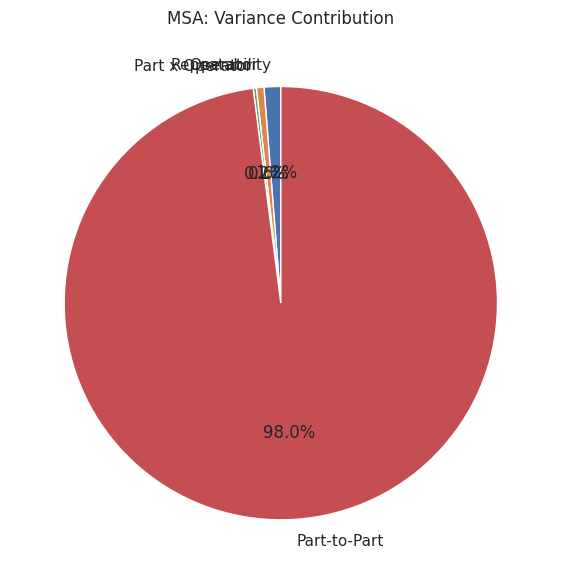

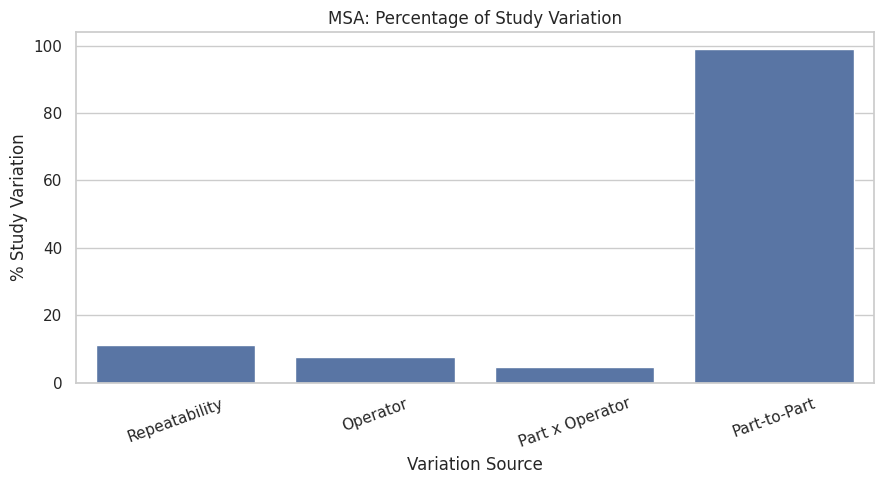

In [10]:
# ============================================================
# 9. Visualize Variance Contribution
# ============================================================

# Show only the main variance components.
# Reproducibility and Total Gage R&R are aggregate
# values and are not added again to the pie chart.

plot_components = pd.Series({
    "Repeatability": var_repeat,
    "Operator": var_operator,
    "Part x Operator": var_interaction,
    "Part-to-Part": var_part
})

plt.figure(figsize=(8, 6))

if plot_components.sum() > 0:

    plt.pie(
        plot_components,
        labels=plot_components.index,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("MSA: Variance Contribution")

else:

    plt.text(
        0.5, 0.5,
        "No positive variance components",
        ha="center",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    FIG_DIR / "13_msa_variance_contribution.png",
    dpi=300
)

plt.show()


# ============================================================
# 10. Visualize Gage R&R Study Variation
# ============================================================

study_components = pd.Series({
    "Repeatability": var_repeat,
    "Operator": var_operator,
    "Part x Operator": var_interaction,
    "Part-to-Part": var_part
})

study_percent = (
    np.sqrt(study_components)
    / np.sqrt(var_total) * 100
    if var_total > 0
    else study_components * np.nan
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=study_percent.index,
    y=study_percent.values
)

plt.ylabel("% Study Variation")
plt.xlabel("Variation Source")
plt.title("MSA: Percentage of Study Variation")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "14_msa_study_variation.png",
    dpi=300
)

plt.show()

In [11]:
# ============================================================
# 11. Export Results
# ============================================================

anova_table.to_csv(
    RESULT_DIR / "msa_anova_table.csv",
    index=False
)

grr_summary.to_csv(
    RESULT_DIR / "msa_variance_components.csv",
    index=False
)

# Save raw variance component estimates
raw_variance = pd.DataFrame({
    "Source": [
        "Repeatability",
        "Operator",
        "Part x Operator",
        "Part-to-Part"
    ],
    "Raw Variance Estimate": [
        var_repeat_raw,
        var_operator_raw,
        var_interaction_raw,
        var_part_raw
    ]
})

raw_variance.to_csv(
    RESULT_DIR / "msa_raw_variance_estimates.csv",
    index=False
)


# ============================================================
# 12. Final Summary
# ============================================================

print("\n" + "=" * 60)
print("MSA ANALYSIS COMPLETED")
print("=" * 60)

print(f"Total records: {len(msa)}")

print(
    f"Repeatability variance: {var_repeat:.6f}"
)

print(
    f"Reproducibility variance: "
    f"{var_reproducibility:.6f}"
)

print(
    f"Total Gage R&R variance: {var_grr:.6f}"
)

print(
    f"Part-to-Part variance: {var_part:.6f}"
)

print(
    f"Total variance: {var_total:.6f}"
)

print(f"ndc: {ndc}")

print("\nResults saved to:")
print(RESULT_DIR)


MSA ANALYSIS COMPLETED
Total records: 60
Repeatability variance: 0.007188
Reproducibility variance: 0.004638
Total Gage R&R variance: 0.011826
Part-to-Part variance: 0.567337
Total variance: 0.579164
ndc: 9

Results saved to:
/content/results


***結果***

**1.ANOVA：**
(Part effect 顯著，Operator effect 顯著)

**Part：p-value 非常小**
不同wafer間的 CD 確實存在顯著差異。

MSA 需要量測系統能夠辨識不同產品之間的差異。如果 10 片 wafer 的 CD 幾乎一模一樣，就很難評估量測系統是否具有足夠的區分能力。

**Operator：p = 0.003808**
不同操作人員的平均量測結果存在統計顯著差異。

與之前的 Operator Error Summary 一致：
- OP01：+0.0416 nm
- OP02：+0.0704 nm
- OP03：-0.0478 nm
OP02 偏高，OP03 偏低。代表即使使用同一台設備，不同操作人員仍可能造成系統性的量測差異。

**Part × Operator：p = 0.216780 **

目前沒有足夠證據顯示不同操作人員對不同 wafer 有不同程度的特殊反應。

例如，沒有明顯證據顯示 OP01 特別容易把某幾片 wafer 量高，而 OP02 卻特別容易把同一批 wafer 量低。

但：不顯著不等於交互作用一定不存在，只代表目前資料沒有足夠證據確認它。


**2.Gauge R&R：量測系統整體表現**
- 重複性變異Repeatability	0.0072
- 操作人員變異Operator	0.0033
- 交互作用變異Part × Operator	0.0013
- 再現性變異Reproducibility	0.0046
- 量測系統總變異Total Gage R&R	0.0118
- 間變異Part-to-Part	0.5673	wafer

*Variance Contribution*

**總變異有 97.96% 來自 wafer 本身的差異，只有 2.04% 來自量測系統。**
代表量測系統可以辨識產品之間的差異，而不是所有結果都被量測誤差淹沒。

*Study Variation*

GRR = 14.29%  條件式可接受,
表示量測系統不是完全沒有問題，但也不是不能使用。

如果這是實際工廠，是否能接受還要看產品 CD 規格、製程窗口、量測用途與客戶要求。

**3.Repeatability vs Reproducibility**

目前 Repeatability 比 Reproducibility 大。
代表*量測系統的隨機重複誤差比操作人員相關的變異更大*。

不過 Operator 的 ANOVA p-value 顯著，表示操作人員之間仍有值得調查的平均偏差。不能只因為 Repeatability 比較大，就忽略人員差異。

改善方向：
- Repeatability：檢查量測設備穩定性、量測定位、環境與重複操作程序。
- Reproducibility：檢查操作 SOP、對焦或取樣位置、操作訓練及人員間的操作差異。

**4.ndc = 9?**

表示這套量測系統可以區分約 9 個不同層級的產品差異。

這也是為什麼不能只看 GRR 的百分比：ndc 可以補充量測系統的區分能力。

**MSA Executive Summary** (詳見04)

交叉式 ANOVA Gauge R&R 分析顯示，量測系統占總變異 2.04%，%Study Variation 為 14.29%，ndc 為 9。

主要變異來源為 wafer 間差異；操作人員效果達統計顯著，建議進一步調查人員間量測偏差，並評估量測系統的重複性。